# Phase 3 — Logistic Regression baseline and stratified five-fold CV

**Academic baseline scenario:** predict subscription before the current marketing campaign starts. All 15 retained predictors remain **Provisional** for feature timing, explicitly approved for this experiment. Fold-specific preprocessing prevents training/validation preprocessing contamination; timestamps/customer histories are still missing, so complete leakage freedom and generalization to unseen customers/future periods are not established.

Only majority-class DummyClassifier and one untuned Logistic Regression configuration are evaluated. No Decision Tree/Random Forest, class weighting, resampling, GridSearchCV, feature selection, threshold optimization or held-out evaluation. No full-development model is fitted.

## Sources and Colab instructions

Reviewed README, project DOCX, Phase 2B summary/data, Phase 2C summary, saved split, notebook, preprocessing module and tests. The current request authorizes a limited academic baseline despite earlier timing-readiness caveats; those caveats remain.

Upload this notebook with `preprocessing.py`, `02_cleaned_dataset.csv` and `03_split_indices.json`, then Run all in Colab. Or mount Drive and set PROJECT_DIR. Standard Colab includes NumPy, pandas, Matplotlib and scikit-learn (>=1.2 required for the existing encoder). Original `dataset.csv` is optional for a byte-integrity check only and is never parsed for modeling. No network/install step is needed. The notebook exports only `04_baseline_summary.md`; figures/results are embedded in notebook outputs when saved. No fitted models, processed CSVs or held-out predictions are exported.

## 1. Verify the saved assignment before reading development rows

An exact SHA-256 match verifies both content and row ordering of the cleaned CSV. Saved zero-based positions are validated for dimensions, uniqueness, bounds, disjointness and full coverage. **No new train-test split is generated.** The CSV loader skips held-out data rows; only development rows are materialized and reordered to the saved development order. Full-file hashes/line counts read bytes for integrity, not held-out labels or feature distributions. Held-out indices are used solely to prove partition separation.


In [1]:
from pathlib import Path
import sys, json, hashlib, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve)
from IPython.display import display
PROJECT_DIR = Path.cwd()  # or a mounted Google Drive project directory
required = ['preprocessing.py','02_cleaned_dataset.csv','03_split_indices.json']
if any(not (PROJECT_DIR/n).is_file() for n in required):
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Place required files in PROJECT_DIR') from exc
    files.upload()
if any(not (PROJECT_DIR/n).is_file() for n in required):
    raise FileNotFoundError('Upload the required inputs listed above')
sys.path.insert(0,str(PROJECT_DIR))
from preprocessing import make_preprocessor, make_cv, FEATURES, CATEGORICAL, NUMERICAL, RECENCY

def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
inputs={n:sha(PROJECT_DIR/n) for n in required}
if (PROJECT_DIR/'dataset.csv').is_file():
    inputs['dataset.csv']=sha(PROJECT_DIR/'dataset.csv')
saved=json.loads((PROJECT_DIR/'03_split_indices.json').read_text())
assert inputs['02_cleaned_dataset.csv']==saved['input_sha256'], 'Input hash/order mismatch: stop'
assert saved['row_count']==41176 and saved['input_file']=='02_cleaned_dataset.csv'
dev_pos=np.asarray(saved['development_indices'],dtype=int)
held_pos=np.asarray(saved['held_out_indices'],dtype=int)
assert len(dev_pos)==32940 and len(held_pos)==8236
assert len(np.unique(dev_pos))==len(dev_pos) and len(np.unique(held_pos))==len(held_pos)
assert not np.intersect1d(dev_pos,held_pos).size
np.testing.assert_array_equal(np.sort(np.r_[dev_pos,held_pos]),np.arange(saved['row_count']))
with (PROJECT_DIR/'02_cleaned_dataset.csv').open('rb') as f:
    assert sum(1 for _ in f)-1==saved['row_count']
keep_positions=set(dev_pos.tolist())
dev=pd.read_csv(PROJECT_DIR/'02_cleaned_dataset.csv',float_precision='round_trip',
                skiprows=lambda line: line>0 and (line-1) not in keep_positions)
assert len(dev)==len(dev_pos)
dev.index=np.sort(dev_pos)
dev=dev.loc[dev_pos].copy()
assert dev.columns.tolist()==FEATURES+['y'] and not dev.isna().any().any()
assert dev.y.isin([0,1]).all()
X=dev[FEATURES].copy(); y=dev.y.copy()
X_snapshot=X.copy(deep=True); y_snapshot=y.copy(deep=True)
print('Only development data loaded:',X.shape, 'positive labels:',int(y.sum()))
print('Saved held-out positions reserved:',len(held_pos),'(no feature/label rows loaded)')
print('Versions:',{'sklearn':sklearn.__version__,'pandas':pd.__version__,'numpy':np.__version__})


Only development data loaded: (32940, 15) positive labels: 3711
Saved held-out positions reserved: 8236 (no feature/label rows loaded)
Versions: {'sklearn': '1.8.0', 'pandas': '2.2.3', 'numpy': '2.3.5'}


## 2. Fixed baselines and common folds

Use StratifiedKFold(n_splits=5, shuffle=True, random_state=42) from the approved factory. Each validation row receives exactly one out-of-fold (OOF) prediction per model. Each fold trains on 26,352 development rows and validates on 6,588. The same stored fold pairs are used for both models.

**Dummy:** `strategy='most_frequent'` learns only the training majority class. It receives a constant one-column placeholder because it does not use customer covariates; no unnecessary preprocessing is fitted. Probability metrics use its positive-class `predict_proba` output, not hard predictions masquerading as scores. A majority-no classifier produces constant zero subscription probabilities: ROC-AUC=0.5 and AP equals validation prevalence.

**Logistic Regression:** a fresh complete Pipeline contains the existing `make_preprocessor('logistic_regression')`, still unfitted, and LogisticRegression(max_iter=1000, random_state=42, C=1.0, class_weight=None, solver='lbfgs'). The library's default L2 regularization is used (no penalty override; this avoids a deprecated penalty argument in sklearn 1.8). No class weighting/resampling. Threshold is fixed at probability >=0.5. No experiment changes C, solver, tolerance, feature set or threshold.

Report precision/recall/F1 with zero_division=0 and positive label 1. ROC-AUC uses probabilities; “PR-AUC” is reported as **Average Precision (AP)**, not trapezoidal PR area. Mean and **sample standard deviation (ddof=1)** summarize five fold scores; these are not independent-replicate confidence intervals.


In [2]:
cv=make_cv()
assert cv.n_splits==5 and cv.shuffle and cv.random_state==42
folds=list(cv.split(X,y))
repeat_folds=list(make_cv().split(X,y))
for (a,b),(aa,bb) in zip(folds,repeat_folds):
    np.testing.assert_array_equal(a,aa); np.testing.assert_array_equal(b,bb)
coverage=np.zeros(len(X),dtype=int)
for tr,va in folds:
    assert len(tr)==26352 and len(va)==6588 and not np.intersect1d(tr,va).size
    assert not set(dev_pos[tr]).intersection(held_pos)
    assert not set(dev_pos[va]).intersection(held_pos)
    coverage[va]+=1
assert np.all(coverage==1)
metric_names=['Accuracy','Precision','Recall','F1','ROC_AUC','Average_Precision']

def evaluate(actual,pred,prob):
    return dict(Accuracy=accuracy_score(actual,pred),
        Precision=precision_score(actual,pred,zero_division=0),
        Recall=recall_score(actual,pred,zero_division=0),
        F1=f1_score(actual,pred,zero_division=0),
        ROC_AUC=roc_auc_score(actual,prob),
        Average_Precision=average_precision_score(actual,prob))

def preprocessor_signature(pre):
    ct=pre.named_steps['preprocessor']
    enc=ct.named_transformers_['categorical']
    num=ct.named_transformers_['numerical']
    rec=ct.named_transformers_['recency']
    return {'categories':[v.tolist() for v in enc.categories_],
        'mean':num.mean_.tolist(),'var':num.var_.tolist(),'scale':num.scale_.tolist(),
        'n':np.asarray(num.n_samples_seen_).tolist(),
        'recency':[rec.mean_,rec.var_,rec.scale_,rec.n_available_],
        'feature_names':pre.get_feature_names_out().tolist()}

oof={name:{'prob':np.full(len(X),np.nan),'pred':np.full(len(X),-1,dtype=int)}
     for name in ['Dummy','LogisticRegression']}
rows=[]; audit_rows=[]; warning_rows=[]; fitted_pipelines=[]


## 3. Fit only inside each development fold and audit fitted state

Each loop constructs a new complete estimator; no preprocessing occurs before that fold's pipeline fit. Assertions compare learned categories, ordinary scaler mean/variance/scale/sample count and conditional recency mean/variance/scale/count against **only that fold's original training rows**. The conditional transformer is reused unchanged.

After validation transforms and prediction, all fitted preprocessing statistics are compared with a pre-validation signature to prove no refitting occurred. Indicator values and unavailable transformed recency zeroes are checked explicitly. The pipelines are kept in memory only to verify object separation and are not persisted or used on held-out data. Warnings and solver iteration counts are recorded rather than silently ignored. These are verification checks, not hyperparameter tuning.


In [3]:
for fold,(tr,va) in enumerate(folds,start=1):
    Xtr=X.iloc[tr]; Xva=X.iloc[va]; ytr=y.iloc[tr]; yva=y.iloc[va]
    dummy=DummyClassifier(strategy='most_frequent')
    dummy.fit(np.zeros((len(tr),1)),ytr)
    dummy_prob=dummy.predict_proba(np.zeros((len(va),1)))[:,list(dummy.classes_).index(1)]
    dummy_pred=dummy.predict(np.zeros((len(va),1)))
    assert np.isfinite(dummy_prob).all()
    oof['Dummy']['prob'][va]=dummy_prob; oof['Dummy']['pred'][va]=dummy_pred
    rows.append({'model':'Dummy','fold':fold,**evaluate(yva,dummy_pred,dummy_prob)})
    pre=make_preprocessor('logistic_regression')
    assert not hasattr(pre.named_steps['preprocessor'],'transformers_')
    estimator=Pipeline([('preprocessing',pre),('classifier',LogisticRegression(
        max_iter=1000,random_state=42,C=1.0,class_weight=None,solver='lbfgs'))])
    started=time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        estimator.fit(Xtr,ytr)
    fit_seconds=time.perf_counter()-started
    for w in caught:
        warning_rows.append({'fold':fold,'category':w.category.__name__,'message':str(w.message)})
    fitted_pipelines.append(estimator)
    ct=pre.named_steps['preprocessor']
    enc=ct.named_transformers_['categorical']; num=ct.named_transformers_['numerical']
    rec=ct.named_transformers_['recency']
    for c,levels in zip(CATEGORICAL,enc.categories_):
        np.testing.assert_array_equal(levels,np.sort(Xtr[c].unique()))
    assert enc.drop is None and enc.handle_unknown=='ignore'
    np.testing.assert_allclose(num.mean_,Xtr[NUMERICAL].mean(),rtol=1e-12,atol=1e-12)
    np.testing.assert_allclose(num.var_,Xtr[NUMERICAL].var(ddof=0),rtol=1e-12,atol=1e-12)
    expected_scale=np.sqrt(Xtr[NUMERICAL].var(ddof=0).to_numpy()); expected_scale[expected_scale==0]=1
    np.testing.assert_allclose(num.scale_,expected_scale,rtol=1e-12,atol=1e-12)
    assert np.all(np.asarray(num.n_samples_seen_)==len(tr))
    observed=Xtr.loc[Xtr.recency_available.eq(1),'recency_days'].to_numpy(dtype=float)
    assert rec.n_available_==len(observed)
    expected_mean=observed.mean() if len(observed) else 0.0
    expected_var=observed.var(ddof=0) if len(observed) else 0.0
    expected_sd=np.sqrt(expected_var) if expected_var>0 else 1.0
    np.testing.assert_allclose([rec.mean_,rec.var_,rec.scale_],[expected_mean,expected_var,expected_sd],rtol=1e-12)
    before=preprocessor_signature(pre)
    transformed=pre.transform(Xva)
    assert transformed.shape[1]==len(pre.get_feature_names_out())
    assert np.isfinite(transformed).all()
    np.testing.assert_array_equal(transformed[:,-1],Xva.recency_available.to_numpy())
    unavailable=Xva.recency_available.eq(0).to_numpy()
    assert (transformed[unavailable,-2]==0).all()
    observed_va=~unavailable
    np.testing.assert_allclose(transformed[observed_va,-2],
        (Xva.loc[observed_va,'recency_days'].to_numpy()-rec.mean_)/rec.scale_)
    probability=estimator.predict_proba(Xva)[:,list(estimator.classes_).index(1)]
    prediction=(probability>=0.5).astype(int)
    np.testing.assert_array_equal(prediction,estimator.predict(Xva))
    assert preprocessor_signature(pre)==before,'Validation changed fitted state'
    assert np.isfinite(probability).all() and ((probability>=0)&(probability<=1)).all()
    clf=estimator.named_steps['classifier']
    assert np.isfinite(clf.coef_).all() and np.isfinite(clf.intercept_).all()
    iterations=int(np.max(clf.n_iter_))
    convergence_count=sum(issubclass(w.category,ConvergenceWarning) for w in caught)
    oof['LogisticRegression']['prob'][va]=probability
    oof['LogisticRegression']['pred'][va]=prediction
    rows.append({'model':'LogisticRegression','fold':fold,**evaluate(yva,prediction,probability)})
    audit_rows.append({'fold':fold,'train_rows':len(tr),'validation_rows':len(va),
        'observed_recency_training_rows':rec.n_available_,'recency_mean':rec.mean_,'recency_sd':rec.scale_,
        'encoded_features':len(pre.get_feature_names_out()),'solver_iterations':iterations,
        'convergence_warnings':convergence_count,'all_fit_warnings':len(caught),
        'positive_predictions':int(prediction.sum()),'fit_seconds':fit_seconds,
        'training_only_checks':'PASS','validation_state_unchanged':'PASS'})
    print('Completed fold',fold,'| iterations',iterations,'| convergence warnings',convergence_count)
assert len({id(p.named_steps['preprocessing']) for p in fitted_pipelines})==5
assert len({id(p.named_steps['preprocessing'].named_steps['preprocessor'].named_transformers_['recency'])
            for p in fitted_pipelines})==5
for name,outputs in oof.items():
    assert np.isfinite(outputs['prob']).all() and np.isin(outputs['pred'],[0,1]).all()
results=pd.DataFrame(rows)
assert np.isfinite(results[metric_names].to_numpy()).all()
audit=pd.DataFrame(audit_rows)
display(audit)
display(pd.DataFrame(warning_rows) if warning_rows else pd.DataFrame({'warnings':['None recorded during all five fits']}))


Completed fold 1 | iterations 36 | convergence warnings 0
Completed fold 2 | iterations 36 | convergence warnings 0
Completed fold 3 | iterations 33 | convergence warnings 0
Completed fold 4 | iterations 27 | convergence warnings 0
Completed fold 5 | iterations 53 | convergence warnings 0


,fold,train_rows,validation_rows,observed_recency_training_rows,recency_mean,recency_sd,encoded_features,solver_iterations,convergence_warnings,all_fit_warnings,positive_predictions,fit_seconds,training_only_checks,validation_state_unchanged
0,1,26352,6588,947,6.070750,3.843597,42,36,0,0,236,0.081664,PASS,PASS
1,2,26352,6588,957,6.022989,3.855744,42,36,0,0,213,0.070123,PASS,PASS
2,3,26352,6588,967,6.024819,3.885566,42,33,0,0,225,0.058781,PASS,PASS
3,4,26352,6588,978,6.208589,3.993022,42,27,0,0,200,0.055106,PASS,PASS
4,5,26352,6588,979,6.097038,3.992815,42,53,0,0,204,0.076567,PASS,PASS


,warnings
0,None recorded during all five fits


## 4. Fold scores and model comparison

Each row is a validation-fold score, with no training-score substitution. The comparison is descriptive: fold scores share training observations, so the standard deviations are not uncertainty bounds for future campaigns. AP uses positive-class probabilities and is explicitly distinguished from trapezoidal PR area.


In [4]:
display(results[['model','fold']+metric_names])
means=results.groupby('model')[metric_names].mean()
stds=results.groupby('model')[metric_names].std(ddof=1)
comparison=pd.DataFrame(index=['Dummy','LogisticRegression'])
for metric in metric_names:
    comparison[metric+' mean ± SD']=[f'{means.loc[m,metric]:.6f} ± {stds.loc[m,metric]:.6f}' for m in comparison.index]
display(comparison)
deltas=(means.loc['LogisticRegression']-means.loc['Dummy']).rename('LR_minus_Dummy_mean')
display(deltas.to_frame())
positive_rate=float(y.mean())
print('Development prevalence:',positive_rate)


Development prevalence: 0.11265938069216758


,model,fold,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision
0,Dummy,1,0.887371,0.000000,0.000000,0.000000,0.500000,0.112629
1,LogisticRegression,1,0.899211,0.665254,0.211590,0.321063,0.774180,0.432213
2,Dummy,2,0.887371,0.000000,0.000000,0.000000,0.500000,0.112629
3,LogisticRegression,2,0.899059,0.680751,0.195418,0.303665,0.759074,0.420763
4,Dummy,3,0.887371,0.000000,0.000000,0.000000,0.500000,0.112629
5,LogisticRegression,3,0.897845,0.653333,0.198113,0.304033,0.742628,0.403407
6,Dummy,4,0.887371,0.000000,0.000000,0.000000,0.500000,0.112629
7,LogisticRegression,4,0.898300,0.680000,0.183288,0.288747,0.770513,0.425606
8,Dummy,5,0.887219,0.000000,0.000000,0.000000,0.500000,0.112781
9,LogisticRegression,5,0.901184,0.725490,0.199192,0.312566,0.764998,0.428919


,Accuracy mean ± SD,Precision mean ± SD,Recall mean ± SD,F1 mean ± SD,ROC_AUC mean ± SD,Average_Precision mean ± SD
Dummy,0.887341 ± 0.000068,0.000000 ± 0.000000,0.000000 ± 0.000000,0.000000 ± 0.000000,0.500000 ± 0.000000,0.112659 ± 0.000068
LogisticRegression,0.899120 ± 0.001282,0.680966 ± 0.027358,0.197520 ± 0.010100,0.306015 ± 0.012010,0.762279 ± 0.012382,0.422181 ± 0.011316


,LR_minus_Dummy_mean
Accuracy,0.011779
Precision,0.680966
Recall,0.197520
F1,0.306015
ROC_AUC,0.262279
Average_Precision,0.309522


## 5. Out-of-fold development diagnostics (threshold fixed at 0.5)

Every probability here was produced by a model that did not train on that observation. These pooled OOF diagnostics are distinct from averaging fold metrics; pooled AP/AUC may differ slightly from mean fold values. No held-out predictions are used. No alternative threshold is selected from these curves. Dummy has no ranking discrimination, so its ROC is diagonal and AP equals development prevalence.


Logistic Regression development OOF: TN,FP,FN,TP = 28884 345 2978 733


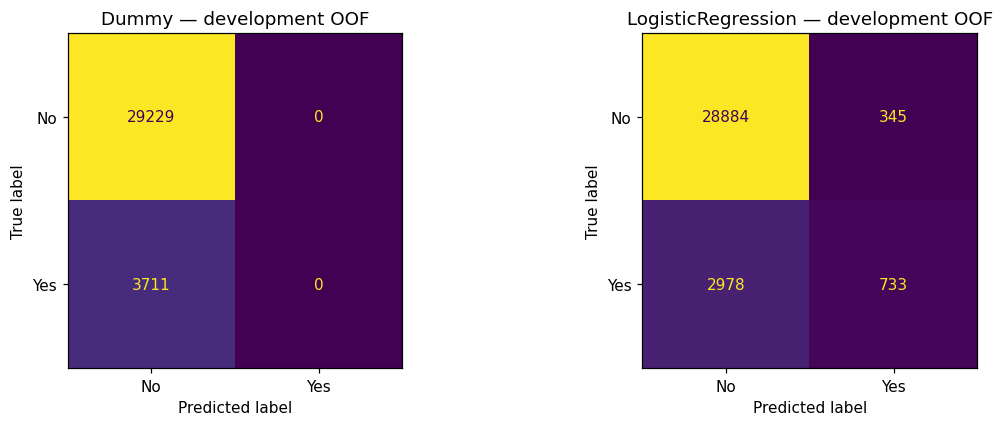

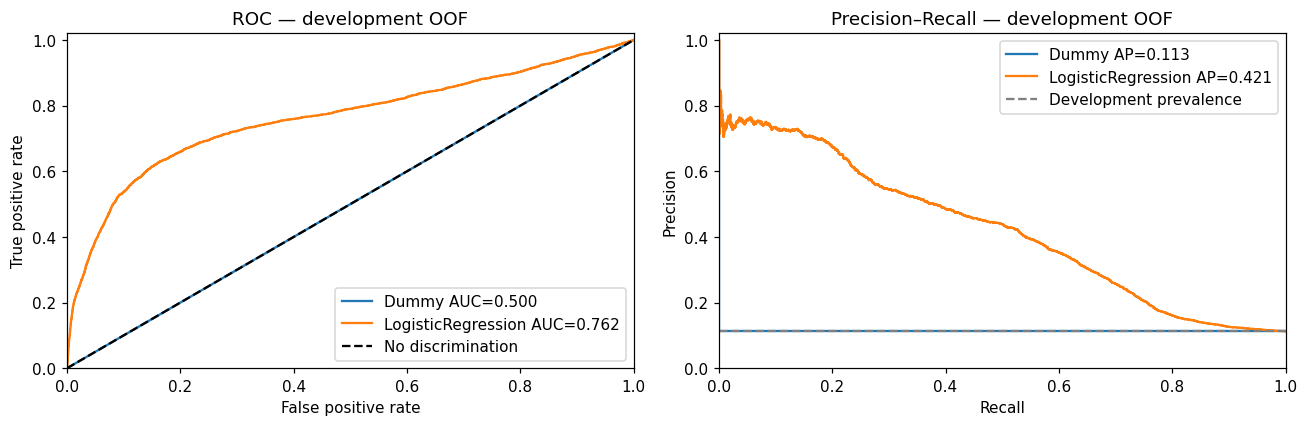

,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision
model,,,,,,
Dummy,0.887341,0.000000,0.000000,0.000000,0.500000,0.112659
LogisticRegression,0.899120,0.679963,0.197521,0.306118,0.762216,0.420750


In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,name in zip(axes,['Dummy','LogisticRegression']):
    ConfusionMatrixDisplay.from_predictions(y,oof[name]['pred'],labels=[0,1],
        display_labels=['No','Yes'],ax=ax,colorbar=False,values_format='d')
    ax.set_title(name+' — development OOF')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
pooled_rows=[]
for name,outputs in oof.items():
    fpr,tpr,_=roc_curve(y,outputs['prob'])
    precision,recall,_=precision_recall_curve(y,outputs['prob'])
    auc=roc_auc_score(y,outputs['prob']);ap=average_precision_score(y,outputs['prob'])
    axes[0].plot(fpr,tpr,label=f'{name} AUC={auc:.3f}')
    axes[1].step(recall,precision,where='post',label=f'{name} AP={ap:.3f}')
    pooled_rows.append({'model':name,**evaluate(y,outputs['pred'],outputs['prob'])})
axes[0].plot([0,1],[0,1],'k--',label='No discrimination')
axes[1].axhline(positive_rate,color='gray',linestyle='--',label='Development prevalence')
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC — development OOF')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–Recall — development OOF')
for ax in axes:ax.legend();ax.set_xlim(0,1);ax.set_ylim(0,1.02)
plt.tight_layout();plt.show()
pooled=pd.DataFrame(pooled_rows).set_index('model')
display(pooled)
cm=confusion_matrix(y,oof['LogisticRegression']['pred'],labels=[0,1])
tn,fp,fn,tp=map(int,cm.ravel())
print('Logistic Regression development OOF: TN,FP,FN,TP =',tn,fp,fn,tp)


## 6. Interpretation and remaining limitations

The generated summary below uses only the measured development-CV results. Higher accuracy alone is insufficient: a majority-no prediction misses every subscriber. A fixed 0.5 threshold can select a relatively small, precise group while missing many positives. Whether that call volume is useful requires campaign capacity, false-positive cost and missed-subscription value, not just a metric.

Retain the present baseline unchanged. Future class-weighting, threshold experiments or resampling **might** change the precision/recall trade-off; no improvement is claimed without a separate approved development-only experiment. This phase performs none of them.

All Provisional predictors: age, job, marital, education, default, housing, loan, previous, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed, recency_available, recency_days. Training-fold-only preprocessing has been checked, but campaign-start feature snapshots, historical recency reference dates, economic publication/revision timing and outcome window remain unresolved. No client identifiers or exact dates exist for client/time-disjoint CV. Random stratification therefore supports a within-dataset academic comparison, not certified performance on unseen customers or future campaign periods. Prior whole-data EDA exposure must also be disclosed. No coefficient ranking, feature selection or causal interpretation is attempted.


## 7. Preserve source artifacts and export a factual summary

Confirm that both CSVs (raw if present), preprocessing module and saved split remain byte-identical; development values and targets remain unchanged in memory. Only the Phase 3 summary is written. Five-fold warnings, scores and audit evidence are retained explicitly; failures raise errors rather than trigger unapproved preprocessing changes.


In [6]:
for name,digest in inputs.items():
    assert sha(PROJECT_DIR/name)==digest, f'{name} changed'
pd.testing.assert_frame_equal(X,X_snapshot,check_exact=True)
pd.testing.assert_series_equal(y,y_snapshot,check_exact=True)
assert (audit.training_only_checks=='PASS').all() and (audit.validation_state_unchanged=='PASS').all()
print('All source integrity and training-only preprocessing checks passed. Held-out rows remain unused.')

def md_table(frame,include_index=False):
    t=frame.reset_index() if include_index else frame.copy()
    def fmt(v):
        return f'{v:.6f}' if isinstance(v,(float,np.floating)) else str(v).replace('|',' / ').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(str,t.columns))+' |',
        '| '+' | '.join(['---']*len(t.columns))+' |']+
        ['| '+' | '.join(fmt(v) for v in row)+' |' for row in t.itertuples(index=False,name=None)])

lr=means.loc['LogisticRegression']; dummy_mean=means.loc['Dummy']
convergence_total=int(audit.convergence_warnings.sum())
warning_text=md_table(pd.DataFrame(warning_rows)) if warning_rows else 'No fit warnings recorded.'
summary=f"""# Phase 3 — Logistic Regression baseline summary

## Scope and data isolation

Academic pre-campaign subscription baseline using approved Provisional predictors. Reused 03_split_indices.json unchanged: 32,940 development rows; 8,236 held-out positions reserved. No new train-test split. Cleaned SHA-256 `{inputs['02_cleaned_dataset.csv']}` verified before saved indices were applied; this binds row ordering as well as values. Saved positions were checked for bounds, uniqueness, coverage and separation. CSV parsing skipped held-out rows, materializing only development features/labels; no held-out feature/label rows were used for fitting, model selection, performance analysis or threshold tuning. Raw dataset was only byte-hashed if present, not parsed for training.

Reviewed README, project DOCX, Phase 2B cleaning summary/data, Phase 2C summary/split/notebook, preprocessing.py and tests/test_preprocessing.py. No approved preprocessing code was replaced or modified. Current request approves this limited experiment while feature-timing concerns remain.

## Model configurations

- DummyClassifier(strategy='most_frequent'), learning only each training-fold majority class. Constant placeholder covariates are used because DummyClassifier ignores customer features. Metrics use predict_proba for class 1 where appropriate.
- LogisticRegression(max_iter=1000, random_state=42, C=1.0, class_weight=None, solver='lbfgs'), default L2 regularization, no resampling. Threshold fixed at 0.5, not optimized. Each new complete sklearn Pipeline is [('preprocessing', make_preprocessor('logistic_regression')), ('classifier', LogisticRegression(...))]. The existing factory is used without modification or prefit.
- Reused full OneHotEncoder, seven-feature StandardScaler and ConditionalRecencyScaler. No full-development preprocessing, no tree/forest models, no GridSearchCV, no hyperparameter/class-weight/threshold trials.

Versions: scikit-learn {sklearn.__version__}, pandas {pd.__version__}, NumPy {np.__version__}. Notebook is Colab-compatible with uploaded module/cleaned CSV/split JSON; scikit-learn >=1.2 is required. Execution was local standard Python, not a live hosted Colab session.

## Cross-validation design and metric definitions

StratifiedKFold(n_splits=5, shuffle=True, random_state=42), identical fold pairs for both baselines. Every fold fits 26,352 and validates 6,588 development rows. Each development observation has exactly one OOF prediction. All original covariates enter each complete fold pipeline without prior global encoding/scaling. Precision/recall/F1 use positive label 1 and zero_division=0. ROC-AUC and Average Precision (AP) use positive probabilities. PR-AUC is represented by AP, not trapezoidal PR area. Five-fold standard deviations below use ddof=1 (sample SD); folds are dependent, so these are descriptive spread, not confidence intervals.

## Individual fold results

{md_table(results[['model','fold']+metric_names])}

## Dummy versus Logistic Regression: mean ± sample SD

{md_table(comparison.rename_axis('model'),include_index=True)}

Mean-score differences LR minus Dummy:

{md_table(deltas.rename_axis('metric').to_frame(),include_index=True)}

## Development-only OOF diagnostics

Plots embedded in 04_logistic_regression_baseline.ipynb show confusion matrices, ROC and Precision–Recall curves; all use pooled OOF development predictions, never held-out observations. Pooled values are separate from fold averages:

{md_table(pooled.rename_axis('model'),include_index=True)}

Logistic Regression OOF confusion matrix at 0.5 (actual rows no/yes; predicted columns no/yes): [[{tn}, {fp}], [{fn}, {tp}]]. It predicts {tp+fp:,} positives ({(tp+fp)/len(y)*100:.2f}% of development records); {tp:,} are true subscriptions and {fp:,} false positives. It misses {fn:,} actual subscriptions. No threshold was selected using these diagnostics.

## Interpretation: observations versus hypotheses

Observed: development subscription prevalence is {positive_rate*100:.4f}%. Dummy accuracy is {dummy_mean.Accuracy:.4f}, despite precision/recall/F1 all zero; predicting no for everyone exploits the majority class while identifying no subscribers. Its ROC-AUC is 0.5 and AP is prevalence, with no discrimination.

Logistic Regression mean accuracy is {lr.Accuracy:.4f}, precision {lr.Precision:.4f}, recall {lr.Recall:.4f}, F1 {lr.F1:.4f}, ROC-AUC {lr.ROC_AUC:.4f} and AP {lr.Average_Precision:.4f}. The measured mean accuracy difference is {deltas.Accuracy:+.4f}; F1 difference {deltas.F1:+.4f}; ROC-AUC difference {deltas.ROC_AUC:+.4f}; AP difference {deltas.Average_Precision:+.4f}. Assessing meaningful business benefit requires call costs/capacity and missed-sale value. These descriptive comparisons are not formal statistical significance or evidence of future deployment performance.

At the fixed threshold, precision and recall must be interpreted together: {lr.Precision*100:.2f}% mean precision versus {lr.Recall*100:.2f}% mean recall. The positive volume above may support prioritization, but usefulness is not established without business constraints. Score ranges across folds: accuracy {results.loc[results.model=='LogisticRegression','Accuracy'].min():.4f}–{results.loc[results.model=='LogisticRegression','Accuracy'].max():.4f}; recall {results.loc[results.model=='LogisticRegression','Recall'].min():.4f}–{results.loc[results.model=='LogisticRegression','Recall'].max():.4f}; ROC-AUC {results.loc[results.model=='LogisticRegression','ROC_AUC'].min():.4f}–{results.loc[results.model=='LogisticRegression','ROC_AUC'].max():.4f}; AP {results.loc[results.model=='LogisticRegression','Average_Precision'].min():.4f}–{results.loc[results.model=='LogisticRegression','Average_Precision'].max():.4f}. These ranges and SDs indicate reasonably consistent baseline results within this random-fold design, with recall varying by about 2.8 percentage points from lowest to highest fold. Logistic Regression improves ranking and positive detection over Dummy in every fold, but its low recall remains a practical limitation. This does not establish stability across unseen customers or future economic periods.

Hypotheses for later approved experiments: class weighting or altered thresholds may change recall/precision; resampling might help or hurt. None has been tested, so no improvement is asserted. This single fixed baseline cannot determine which alternative would help. Do not alter the held-out set based on these development results.

## Convergence and training-fold leakage audit

{md_table(audit.drop(columns=['fit_seconds']))}

ConvergenceWarning count: {convergence_total}. Solver iterations range {int(audit.solver_iterations.min())}–{int(audit.solver_iterations.max())}, max_iter=1000. Finite coefficients/probabilities/transformed validation matrices were verified. If warnings are present they are disclosed below; no hidden solver/tuning changes were made.

Fit-warning log:

{warning_text}

All five complete estimator pipelines are distinct, with separate fitted preprocessing and conditional-transformer objects. For each fold, OHE vocabularies match only that fold's training levels; ordinary scaler mean, population variance, scale and sample count match its training rows; recency mean/variance/scale/count match only availability=1 training rows. Validation transforms preserve every audited fitted parameter; unavailable transformed recency remains zero and the availability bit is unscaled. Training/validation indices are disjoint, confined to the saved development partition, and OOF coverage is exactly once per row. No preprocessors were fitted on all development data before CV. No NaN/infinity or input mutation was detected.

Source hash checks for all supplied inputs passed after execution. Saved split and raw/cleaned datasets remain unchanged; the preprocessing module remains unchanged. No final whole-development fit, held-out transform/prediction, or model serialization occurred.

## Remaining limitations and team discussion

All 15 features remain Provisional: {', '.join(FEATURES)}. Preprocessing leakage is addressed by fold-specific complete pipelines; feature-timing leakage is unresolved. Verify pre-campaign customer/status snapshots, previous-history cutoff, pdays reference date, economic publication/revision vintages and target outcome/follow-up window. A last-contact-period economic value may be unavailable at campaign start. Neither these metrics nor proper preprocessing certify timing safety.

No customer IDs/full dates means stratified random folds may share clients or economic periods; results cannot guarantee unseen-customer or future-campaign performance. Repeated predictor profiles remain by approval. Prior full-data EDA exposure must be disclosed. Rare categories can be absent in a fold and are handled as unseen without global vocabulary learning. Economic collinearity may complicate coefficient interpretation; no feature selection or causal inference is performed.

## Recommended next steps (not executed)

1. Review baseline results, call-capacity/error costs and unresolved feature availability before approving further experiments.
2. If approved, investigate class weighting and threshold selection strictly on development data with properly nested fold preprocessing; assess any added complexity against this saved baseline. No resampling benefit is claimed.
3. Obtain customer/date metadata for an approved group/time validation design if future/generalization claims are needed; do not replace the saved split without approval.
4. Keep the held-out test reserved for a later explicitly approved final evaluation. Do not start another model family or tune now.

Deliverables: executed 04_logistic_regression_baseline.ipynb and this 04_baseline_summary.md, saved directly in the repository. No commit or push is made pending approval. Phase 3 stops here.
"""
(PROJECT_DIR/'04_baseline_summary.md').write_text(summary,encoding='utf-8')
print('Saved 04_baseline_summary.md. No next-phase work, commit or push.')


All source integrity and training-only preprocessing checks passed. Held-out rows remain unused.
Saved 04_baseline_summary.md. No next-phase work, commit or push.
